<a href="https://colab.research.google.com/github/Vas0400/Analitica-de-Negocios/blob/main/Proyecto_Final_Analitica_Churn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Final – Analítica de Negocios
## Predicción de abandono (churn), segmentación y pronóstico de gasto de clientes de e-commerce

**Universidad EAFIT – Analítica de Negocios (Clase 1642)**
**Integrantes:** Samuel Vásquez  · Lucas Palacio · Jeronimo Estrada

**Base de datos:** *Customers Transactions* – Kaggle (fares279/customers-transactions)

Link Video : https://youtu.be/M1vnRPF8SLE

## 1. Introducción

En el comercio electrónico, conseguir un cliente nuevo cuesta varias veces más que conservar uno actual. Por eso las empresas necesitan saber **qué clientes se van a ir (churn)**, **qué tipos de clientes tienen** y **cuánto va a gastar cada uno**. Con esa información pueden enfocar sus campañas de retención y su presupuesto de marketing donde más impacto generan.

En este proyecto usamos una base de datos de 10.000 clientes de una tienda en línea con información demográfica, de comportamiento de compra y de satisfacción. Aplicamos tres modelos vistos en clase: **K-means** (agrupamiento), **Árbol de Decisión** y **Red Neuronal MLP** (clasificación del churn) y una **Red Neuronal MLP de regresión** (pronóstico del gasto del cliente).

## 2. Definición del problema

**Necesidad de negocio:** la empresa pierde cerca del 11% de sus clientes y no sabe quiénes son ni por qué se van. Tampoco tiene una forma de estimar el valor de cada cliente para priorizar acciones.

**Preguntas de negocio:**
1. ¿Qué grupos (segmentos) de clientes existen según su comportamiento de compra?
2. ¿Podemos predecir qué clientes van a abandonar la empresa (churn)?
3. ¿Qué variables explican más el abandono?
4. ¿Podemos pronosticar cuánto va a gastar un cliente a partir de su perfil y comportamiento?

## 3. Objetivos

**Objetivo general:** construir modelos de analítica que ayuden a la empresa a retener clientes y a priorizar sus inversiones comerciales.

**Objetivos específicos:**
- Describir y preparar la base de datos de clientes.
- Segmentar a los clientes con **K-means** y describir cada grupo.
- Clasificar a los clientes en *churn / no churn* con un **Árbol de Decisión** y una **Red Neuronal (MLP)**, y comparar su desempeño.
- Pronosticar el **gasto total del cliente** con una **Red Neuronal MLP de regresión**.
- Proponer recomendaciones de negocio a partir de los resultados.

## 4. Recopilar y preparar los datos

### 4.1 Importación de librerías y descarga de los datos

In [ ]:
# Se importan las librerías
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
import warnings; warnings.filterwarnings("ignore")

In [ ]:
# Descarga de la base de datos desde Kaggle
path = kagglehub.dataset_download("fares279/customers-transactions")
archivo = glob.glob(path + "/**/*.csv", recursive=True)[0]
df = pd.read_csv(archivo)
print(df.shape)
df.head()

100%|██████████| 224k/224k [00:00<00:00, 27.5MB/s]

Extracting files...
(10000, 14)


,customer_id,age,gender,country,annual_income,spending_score,num_purchases,avg_purchase_value,membership_years,website_visits_per_month,cart_abandon_rate,churned,feedback_text,last_purchase_date
0,1,37,Male,Germany,85886,14,18,41.20,6,20,0.95,0,Very satisfied with my purchase.,2025-06-22
1,2,40,Male,India,41041,4,10,31.73,4,29,0.21,0,Good quality and value for money.,2025-10-17
2,3,69,Female,Australia,143869,59,39,65.96,12,26,0.08,0,Excellent customer service.,2025-07-01
3,4,30,Male,UK,87261,45,34,51.87,12,7,0.61,0,Good quality and value for money.,2025-08-17
4,5,69,Female,UK,110678,40,38,59.64,13,16,0.49,0,Excellent customer service.,2025-06-21


### 4.2 Descripción de la base de datos

La base tiene **10.000 registros (clientes)** y **14 variables**, sin valores faltantes.

| Variable | Tipo | Descripción | Uso en el proyecto |
|---|---|---|---|
| customer_id | Numérica (ID) | Identificador del cliente | Se elimina (no aporta información) |
| age | Numérica | Edad del cliente (18–70 años) | Explicativa |
| gender | Categórica | Género (Male / Female) | Explicativa |
| country | Categórica | País (10 países) | Explicativa |
| annual_income | Numérica | Ingreso anual en USD | Explicativa |
| spending_score | Numérica | Puntaje de gasto asignado por la tienda (1–100) | Explicativa / agrupamiento |
| num_purchases | Numérica | Número de compras realizadas | Agrupamiento / parte del pronóstico |
| avg_purchase_value | Numérica | Valor promedio de cada compra (USD) | Agrupamiento / parte del pronóstico |
| membership_years | Numérica | Años como miembro | Explicativa |
| website_visits_per_month | Numérica | Visitas mensuales al sitio web | Explicativa |
| cart_abandon_rate | Numérica | Tasa de abandono del carrito (0–1) | Explicativa |
| **churned** | **Categórica binaria** | **1 = el cliente abandonó, 0 = sigue activo** | **Variable objetivo de clasificación** |
| feedback_text | Texto | Comentario del cliente (12 frases distintas) | Se transforma en sentimiento (positivo/neutral/negativo) |
| last_purchase_date | Fecha | Fecha de la última compra | Se transforma en "días desde la última compra" (recencia) |

**Variable de clasificación:** `churned` (categórica).
**Variable de agrupamiento:** segmentos creados con K-means a partir del comportamiento de compra.
**Variable de pronóstico:** `gasto_total` = `num_purchases` × `avg_purchase_value` (numérica, en USD).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               10000 non-null  int64  
 1   age                       10000 non-null  int64  
 2   gender                    10000 non-null  object 
 3   country                   10000 non-null  object 
 4   annual_income             10000 non-null  int64  
 5   spending_score            10000 non-null  int64  
 6   num_purchases             10000 non-null  int64  
 7   avg_purchase_value        10000 non-null  float64
 8   membership_years          10000 non-null  int64  
 9   website_visits_per_month  10000 non-null  int64  
 10  cart_abandon_rate         10000 non-null  float64
 11  churned                   10000 non-null  int64  
 12  feedback_text             10000 non-null  object 
 13  last_purchase_date        10000 non-null  object 
dtypes: floa

In [ ]:
print(df.describe().T.round(2).to_string())

                            count      mean       std       min       25%       50%        75%        max
customer_id               10000.0   5000.50   2886.90      1.00   2500.75   5000.50    7500.25   10000.00
age                       10000.0     44.05     15.40     18.00     31.00     44.00      57.00      70.00
annual_income             10000.0  86067.68  38986.79  20028.00  55345.50  78339.50  115570.50  179960.00
spending_score            10000.0     50.92     28.75      1.00     26.00     51.00      75.00     100.00
num_purchases             10000.0     22.58     10.16      1.00     14.00     22.00      31.00      49.00
avg_purchase_value        10000.0     47.45     11.21     16.75     39.50     46.99      55.08      83.27
membership_years          10000.0      6.34      4.68      0.00      2.00      6.00      10.00      15.00
website_visits_per_month  10000.0     15.58      8.66      1.00      8.00     16.00      23.00      30.00
cart_abandon_rate         10000.0      0.50   

In [ ]:
# Variables categóricas
for c in ["gender", "country", "feedback_text"]:
    print(df[c].value_counts(), "\n")

gender
Male      5063
Female    4937
Name: count, dtype: int64 

country
USA             2389
India           1524
Brazil          1025
UK              1013
Germany         1008
Canada           828
Australia        684
France           640
Japan            495
South Africa     394
Name: count, dtype: int64 

feedback_text
Love the products and fast shipping.          1542
Great experience, will shop again!            1510
Very satisfied with my purchase.              1507
Excellent customer service.                   1491
The website is easy to use.                   1437
Good quality and value for money.             1423
Poor quality, item broke after a week.         200
Customer service was unhelpful.                187
Shipping was too slow.                         183
The product did not match the description.     181
Difficult to navigate the website.             174
I will not be shopping here again.             165
Name: count, dtype: int64 



### 4.3 Análisis exploratorio

churned
0    0.891
1    0.109
Name: proportion, dtype: float64


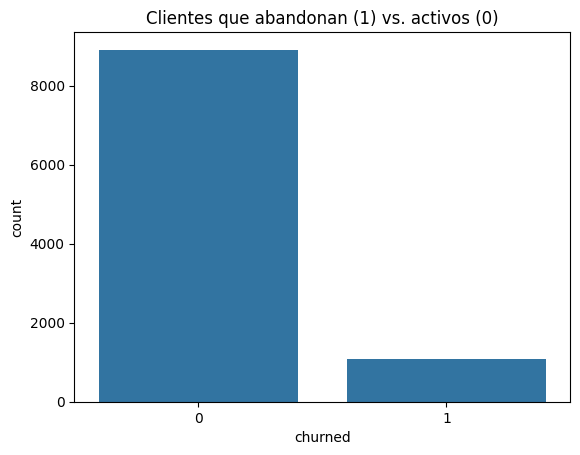

In [ ]:
# Proporción de clientes que abandonan
print(df["churned"].value_counts(normalize=True).round(3))
sns.countplot(x="churned", data=df)
plt.title("Clientes que abandonan (1) vs. activos (0)")
plt.show()

In [ ]:
# Comparación de las variables numéricas entre clientes activos y que abandonan
num_vars = ["age", "annual_income", "spending_score", "num_purchases", "avg_purchase_value",
            "membership_years", "website_visits_per_month", "cart_abandon_rate"]
print(df.groupby("churned")[num_vars].mean().T.round(2).to_string())

churned                          0         1
age                          44.20     42.78
annual_income             86119.56  85643.60
spending_score               53.38     30.82
num_purchases                23.19     17.53
avg_purchase_value           47.96     43.28
membership_years              6.52      4.87
website_visits_per_month     15.96     12.49
cart_abandon_rate             0.49      0.63


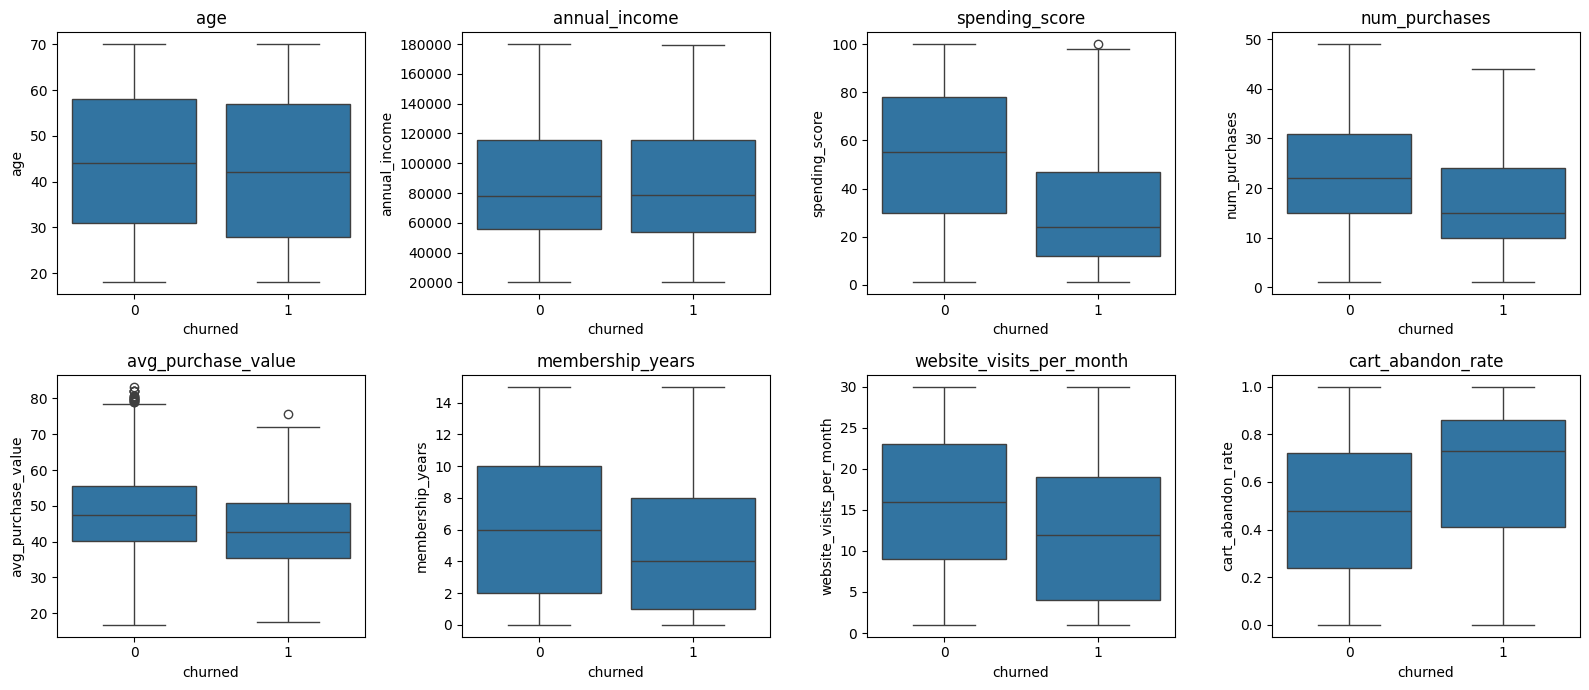

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, v in zip(axes.ravel(), num_vars):
    sns.boxplot(x="churned", y=v, data=df, ax=ax)
    ax.set_title(v)
plt.tight_layout(); plt.show()

In [ ]:
# Tasa de churn por país y por comentario del cliente
print(df.groupby("country")["churned"].mean().sort_values(ascending=False).round(3), "\n")
print(df.groupby("feedback_text")["churned"].mean().sort_values(ascending=False).round(3))

country
UK              0.128
France          0.120
Japan           0.117
South Africa    0.117
Germany         0.112
Brazil          0.110
India           0.109
USA             0.100
Australia       0.098
Canada          0.097
Name: churned, dtype: float64 

feedback_text
Customer service was unhelpful.               1.0
Difficult to navigate the website.            1.0
Poor quality, item broke after a week.        1.0
I will not be shopping here again.            1.0
The product did not match the description.    1.0
Shipping was too slow.                        1.0
Good quality and value for money.             0.0
Excellent customer service.                   0.0
Love the products and fast shipping.          0.0
Great experience, will shop again!            0.0
The website is easy to use.                   0.0
Very satisfied with my purchase.              0.0
Name: churned, dtype: float64


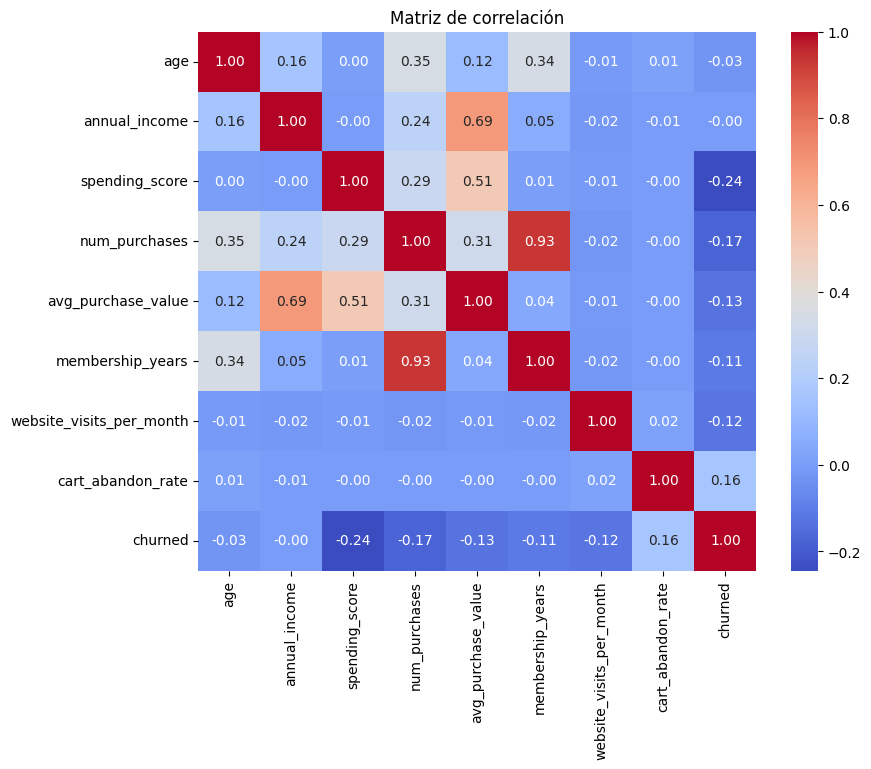

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_vars + ["churned"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

### 4.4 Preparación de los datos (ingeniería de variables)

- **Recencia:** días entre la última compra de cada cliente y la fecha más reciente de la base.
- **Sentimiento:** cada uno de los 12 comentarios se clasifica como positivo (1), neutral (0) o negativo (-1).
- **Gasto total:** `num_purchases × avg_purchase_value`, que será la variable a pronosticar.
- Se elimina `customer_id` porque es solo un identificador.

In [ ]:
df["last_purchase_date"] = pd.to_datetime(df["last_purchase_date"])
df["recencia_dias"] = (df["last_purchase_date"].max() - df["last_purchase_date"]).dt.days

# Clasificación del sentimiento de cada comentario
frases = df["feedback_text"].unique()
print(frases)

['Very satisfied with my purchase.' 'Good quality and value for money.'
 'Excellent customer service.'
 'The product did not match the description.'
 'Love the products and fast shipping.' 'The website is easy to use.'
 'Great experience, will shop again!' 'I will not be shopping here again.'
 'Customer service was unhelpful.'
 'Poor quality, item broke after a week.'
 'Difficult to navigate the website.' 'Shipping was too slow.']


In [ ]:
negativas = ["Poor quality, item broke after a week.", "Customer service was unhelpful.", "Shipping was too slow.",
             "The product did not match the description.", "Difficult to navigate the website.",
             "I will not be shopping here again."]
def sentimiento(t):
    return -1 if t in negativas else 1
df["sentimiento"] = df["feedback_text"].apply(sentimiento)
print(df.groupby(["feedback_text"])["sentimiento"].first().sort_values())
print(pd.crosstab(df["sentimiento"], df["churned"]))

feedback_text
Customer service was unhelpful.              -1
Difficult to navigate the website.           -1
Poor quality, item broke after a week.       -1
I will not be shopping here again.           -1
The product did not match the description.   -1
Shipping was too slow.                       -1
Good quality and value for money.             1
Excellent customer service.                   1
Love the products and fast shipping.          1
Great experience, will shop again!            1
The website is easy to use.                   1
Very satisfied with my purchase.              1
Name: sentimiento, dtype: int64
churned         0     1
sentimiento            
-1              0  1090
 1           8910     0


In [ ]:
df["gasto_total"] = df["num_purchases"] * df["avg_purchase_value"]
datos = df.drop(columns=["customer_id", "feedback_text", "last_purchase_date"])
datos.head()

,age,gender,country,annual_income,spending_score,num_purchases,avg_purchase_value,membership_years,website_visits_per_month,cart_abandon_rate,churned,recencia_dias,sentimiento,gasto_total
0,37,Male,Germany,85886,14,18,41.20,6,20,0.95,0,127,1,741.60
1,40,Male,India,41041,4,10,31.73,4,29,0.21,0,10,1,317.30
2,69,Female,Australia,143869,59,39,65.96,12,26,0.08,0,118,1,2572.44
3,30,Male,UK,87261,45,34,51.87,12,7,0.61,0,71,1,1763.58
4,69,Female,UK,110678,40,38,59.64,13,16,0.49,0,128,1,2266.32


## 5. Definición de los modelos, método de trabajo y métricas

| Modelo | Tipo | Variable objetivo | Métricas |
|---|---|---|---|
| **K-means** | Agrupamiento (no supervisado) | — (crea segmentos) | Índice Silhouette |
| **Árbol de Decisión** + GridSearchCV | Clasificación | `churned` | Exactitud, Sensibilidad (Recall), Especificidad, Precisión, F1, AUC-ROC |
| **Red Neuronal MLP** (MLPClassifier) | Clasificación | `churned` | Las mismas, para comparar con el árbol |
| **Red Neuronal MLP** (MLPRegressor) | Pronóstico (regresión) | `gasto_total` | MAE, RMSE, R² (comparado con una regresión lineal base) |

**Método paso a paso:**
1. Preprocesamiento con *pipelines*: imputación, `StandardScaler` para variables numéricas y `OneHotEncoder` para categóricas (como en las clases de K-means y Redes Neuronales).
2. División de los datos en entrenamiento (60%), validación (20%) y prueba (20%), estratificando por `churned`.
3. Búsqueda de hiperparámetros con `GridSearchCV` y validación cruzada de 5 pliegues.
4. Evaluación en el conjunto de prueba con las métricas de la tabla.

**Nota sobre el desbalance:** solo ~11% de los clientes abandonan. Un modelo que diga "nadie se va" tendría ~89% de exactitud y no serviría. Por eso usamos `class_weight="balanced"` en el árbol, optimizamos por **F1** y le damos más importancia a la **Sensibilidad** (encontrar a los que se van).

## 6. Desplegar los modelos y validar (resultados)

### 6.1 Modelo 1 – K-means: segmentación de clientes
Se agrupan los clientes con las variables de comportamiento de compra y valor.

k=2  silhouette=0.183
k=3  silhouette=0.167
k=4  silhouette=0.183
k=5  silhouette=0.160
k=6  silhouette=0.154
k=7  silhouette=0.145
k=8  silhouette=0.142

Mejor k=2 con silhouette=0.183


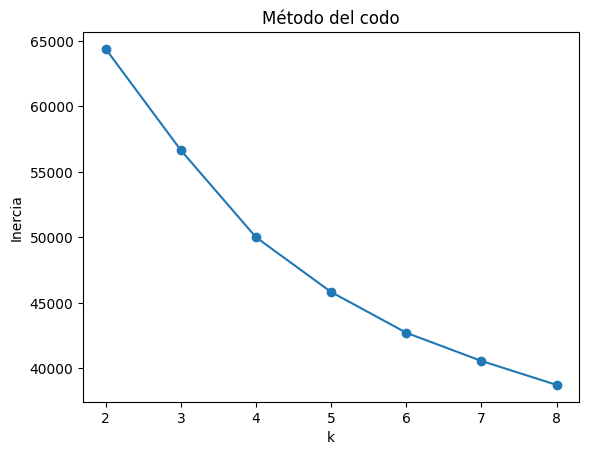

In [ ]:
vars_seg = ["annual_income", "spending_score", "num_purchases", "avg_purchase_value",
            "membership_years", "website_visits_per_month", "cart_abandon_rate", "recencia_dias"]
Xseg = StandardScaler().fit_transform(datos[vars_seg])

best_k, best_sil = None, -1.0
inercias = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(Xseg)
    sil = silhouette_score(Xseg, labels)
    inercias.append(km.inertia_)
    print(f"k={k}  silhouette={sil:.3f}")
    if sil > best_sil:
        best_k, best_sil = k, sil
        best_labels, best_km = labels, km
print(f"\nMejor k={best_k} con silhouette={best_sil:.3f}")

plt.plot(range(2, 9), inercias, marker="o")
plt.title("Método del codo"); plt.xlabel("k"); plt.ylabel("Inercia"); plt.show()

Silhouette k=4: 0.183


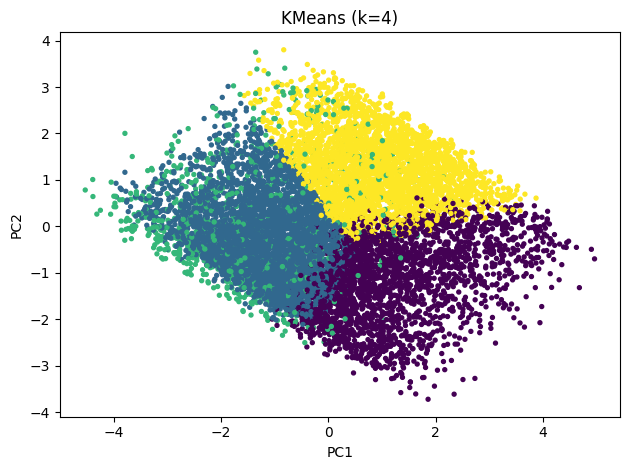

In [ ]:
# Para efectos de negocio se usa K = 4 segmentos (más fácil de accionar); se reporta su silhouette
K_NEG = 4
km4 = KMeans(n_clusters=K_NEG, n_init=10, random_state=42)
datos["segmento"] = km4.fit_predict(Xseg)
print("Silhouette k=4:", round(silhouette_score(Xseg, datos["segmento"]), 3))

X2 = PCA(n_components=2, random_state=42).fit_transform(Xseg)
plt.scatter(X2[:, 0], X2[:, 1], c=datos["segmento"], s=8, cmap="viridis")
plt.title(f"KMeans (k={K_NEG})"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

In [ ]:
# Perfil de cada segmento
perfil = datos.groupby("segmento")[vars_seg + ["gasto_total", "churned"]].mean().round(2)
perfil["n_clientes"] = datos["segmento"].value_counts().sort_index()
print(perfil.T.to_string())

segmento                          0         1         2         3
annual_income             130618.24  66146.31  83390.97  74690.28
spending_score                65.21     44.47     29.44     52.91
num_purchases                 25.18     14.19     16.89     32.74
avg_purchase_value            60.69     41.57     42.48     45.13
membership_years               5.82      2.98      4.68     11.57
website_visits_per_month      15.46     16.25     12.61     15.61
cart_abandon_rate              0.50      0.48      0.65      0.49
recencia_dias                 95.86     94.23    521.60     94.96
gasto_total                 1544.86    594.79    739.43   1495.19
churned                        0.03      0.04      1.00      0.03
n_clientes                  2491.00   3792.00    788.00   2929.00


### 6.2 Modelo 2 – Árbol de Decisión: clasificación del churn

**⚠️ Hallazgo importante (fuga de información o *data leakage*):** en el análisis exploratorio vimos que **todos** los clientes con un comentario negativo abandonaron y **ninguno** con comentario positivo lo hizo. Si el comentario entra al modelo, este acierta el 100% de los casos, pero es un resultado engañoso: el comentario negativo probablemente se escribe **cuando el cliente ya se está yendo**, así que no sirve para anticipar el abandono. Lo mismo pasa con la **recencia** (días desde la última compra): el segmento de clientes inactivos de K-means tiene 100% de churn, lo que indica que en esta base el *churn* se define precisamente por llevar mucho tiempo sin comprar. Por eso **excluimos `feedback_text`, `sentimiento` y `recencia_dias` de los modelos de clasificación** y predecimos el churn solo con variables de perfil y comportamiento, que sí están disponibles antes de que el cliente se vaya.

In [ ]:
X_cat = datos[["gender", "country"]]
X_num = datos[["age", "annual_income", "spending_score", "num_purchases", "avg_purchase_value",
               "membership_years", "website_visits_per_month", "cart_abandon_rate"]]
y = datos["churned"]

OE = OrdinalEncoder()
X_cat_encod = pd.DataFrame(OE.fit_transform(X_cat), columns=X_cat.columns, index=X_cat.index)
X = pd.concat([X_cat_encod, X_num], axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
modDTC = DecisionTreeClassifier(criterion="entropy", class_weight="balanced", random_state=42)
Grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 10, 20, 50],
    "min_samples_leaf": [1, 5, 10, 20],
}
Grid_S = GridSearchCV(estimator=modDTC, param_grid=Grid, cv=5, scoring="f1", n_jobs=-1, refit=True)
Grid_S.fit(X_train, y_train)
print("Mejores hiperparámetros:", Grid_S.best_params_)

best_tree = Grid_S.best_estimator_
y_pred = best_tree.predict(X_test)
y_proba = best_tree.predict_proba(X_test)[:, 1]
print(classification_report(y_test, y_pred))

Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 20, 'min_samples_split': 50}
              precision    recall  f1-score   support

           0       0.98      0.64      0.77      1782
           1       0.23      0.87      0.36       218

    accuracy                           0.66      2000
   macro avg       0.60      0.75      0.57      2000
weighted avg       0.89      0.66      0.73      2000



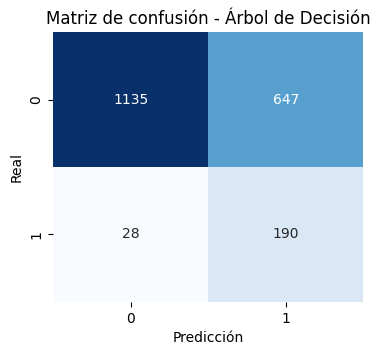

Exactitud                0.662
Tasa de error            0.338
Sensibilidad (Recall)    0.872
Especificidad            0.637
Precisión                0.227
F1                       0.360
AUC-ROC                  0.832


In [ ]:
def metricas(y_true, y_pred, y_proba, nombre):
    cm = confusion_matrix(y_true, y_pred)
    VN, FP, FN, VP = cm.ravel()
    r = {
        "Modelo": nombre,
        "Exactitud": (VP + VN) / cm.sum(),
        "Tasa de error": (FN + FP) / cm.sum(),
        "Sensibilidad (Recall)": VP / (VP + FN),
        "Especificidad": VN / (VN + FP),
        "Precisión": VP / (VP + FP) if (VP + FP) > 0 else 0,
        "F1": f1_score(y_true, y_pred),
        "AUC-ROC": roc_auc_score(y_true, y_proba),
    }
    plt.figure(figsize=(4, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap="Blues")
    plt.title(f"Matriz de confusión - {nombre}"); plt.xlabel("Predicción"); plt.ylabel("Real")
    plt.show()
    return r

res_tree = metricas(y_test, y_pred, y_proba, "Árbol de Decisión")
print(pd.Series(res_tree).drop("Modelo").astype(float).round(3).to_string())

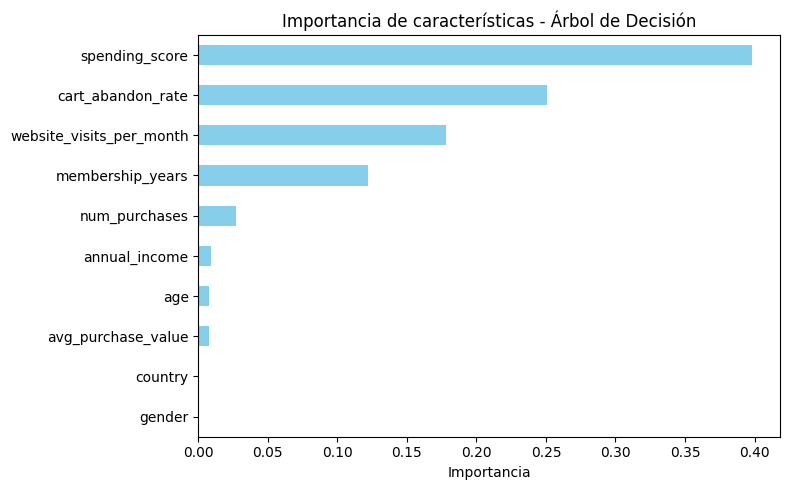

spending_score              0.0943
cart_abandon_rate           0.0578
website_visits_per_month    0.0396
membership_years            0.0116
num_purchases               0.0031
gender                      0.0000
country                     0.0000
annual_income               0.0000
avg_purchase_value          0.0000
age                        -0.0004
dtype: float64


In [ ]:
# Importancia de características
importances = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values()
plt.figure(figsize=(8, 5))
importances.tail(10).plot(kind="barh", color="skyblue")
plt.title("Importancia de características - Árbol de Decisión"); plt.xlabel("Importancia")
plt.tight_layout(); plt.show()

pi = permutation_importance(best_tree, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1, scoring="f1")
print(pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False).round(4))

### 6.3 Modelo 3 – Red Neuronal MLP: clasificación del churn (comparación)

Entrenamiento balanceado: {0: 5346, 1: 5346}
AUC validación: 0.757
Umbral óptimo (validación): 0.10  F1 valid = 0.330
              precision    recall  f1-score   support

           0       0.94      0.71      0.81      1782
           1       0.21      0.61      0.31       218

    accuracy                           0.70      2000
   macro avg       0.57      0.66      0.56      2000
weighted avg       0.86      0.70      0.75      2000



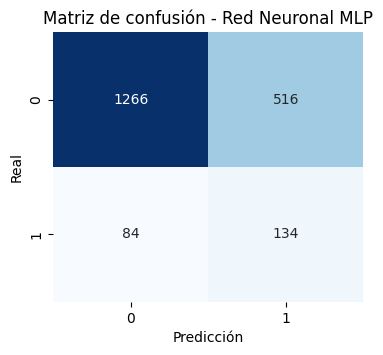

In [ ]:
Xr = datos.drop(columns=["churned", "segmento", "gasto_total", "sentimiento", "recencia_dias"])
X_train_full, X_test_n, y_train_full, y_test_n = train_test_split(Xr, y, test_size=0.20, random_state=42, stratify=y)
X_train_n, X_valid_n, y_train_n, y_valid_n = train_test_split(X_train_full, y_train_full, test_size=0.25, random_state=42, stratify=y_train_full)

Preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]),
     make_column_selector(dtype_include=np.number)),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]),
     make_column_selector(dtype_exclude=np.number))
])

# Nota: con early_stopping la red se detenía muy pronto porque la exactitud de validación ya era ~89%
# (prediciendo que nadie se va). Por eso se entrena sin early_stopping y con regularización L2 más fuerte.
mlp = MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", solver="adam", alpha=1e-2,
                    learning_rate_init=1e-3, max_iter=400, early_stopping=False, random_state=42)
pipe = Pipeline([("prep", Preprocessor), ("model", mlp)])

# La red no admite class_weight, así que balanceamos el entrenamiento duplicando (sobremuestreo) a los clientes que abandonan
from sklearn.utils import resample
tr = pd.concat([X_train_n, y_train_n], axis=1)
minoria = tr[tr["churned"] == 1]
mayoria = tr[tr["churned"] == 0]
tr_bal = pd.concat([mayoria, resample(minoria, replace=True, n_samples=len(mayoria), random_state=42)])
print("Entrenamiento balanceado:", tr_bal["churned"].value_counts().to_dict())
pipe.fit(tr_bal.drop(columns="churned"), tr_bal["churned"])
print("AUC validación:", round(roc_auc_score(y_valid_n, pipe.predict_proba(X_valid_n)[:, 1]), 3))

# El churn es poco frecuente: se elige el umbral de probabilidad que maximiza el F1 en VALIDACIÓN
p_val = pipe.predict_proba(X_valid_n)[:, 1]
umbrales = np.arange(0.10, 0.95, 0.01)
f1s = [f1_score(y_valid_n, (p_val >= u).astype(int)) for u in umbrales]
umbral = umbrales[int(np.argmax(f1s))]
print(f"Umbral óptimo (validación): {umbral:.2f}  F1 valid = {max(f1s):.3f}")

p_test = pipe.predict_proba(X_test_n)[:, 1]
y_pred_mlp = (p_test >= umbral).astype(int)
print(classification_report(y_test_n, y_pred_mlp))
res_mlp = metricas(y_test_n, y_pred_mlp, p_test, "Red Neuronal MLP")

                   Exactitud  Tasa de error  Sensibilidad (Recall)  Especificidad  Precisión     F1  AUC-ROC
Modelo                                                                                                      
Árbol de Decisión      0.662          0.338                  0.872          0.637      0.227  0.360    0.832
Red Neuronal MLP       0.700          0.300                  0.615          0.710      0.206  0.309    0.743


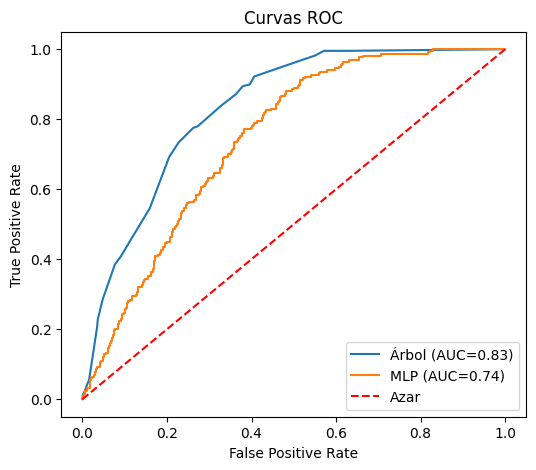

In [ ]:
# Comparación de los dos clasificadores y curvas ROC
comparacion = pd.DataFrame([res_tree, res_mlp]).set_index("Modelo").round(3)
print(comparacion.to_string())

plt.figure(figsize=(6, 5))
for nombre, yt, pr in [("Árbol", y_test, y_proba), ("MLP", y_test_n, p_test)]:
    fpr, tpr, _ = roc_curve(yt, pr)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(yt, pr):.2f})")
plt.plot([0, 1], [0, 1], "r--", label="Azar")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Curvas ROC"); plt.legend(); plt.show()

### 6.4 Modelo 4 – Red Neuronal MLP de regresión: pronóstico del gasto total

Se pronostica `gasto_total` **sin** usar `num_purchases` ni `avg_purchase_value` (porque con ellas el gasto se calcula directamente). Así el modelo estima el gasto de un cliente a partir de su perfil y comportamiento en el sitio. Se compara contra una **regresión lineal** como línea base.

In [ ]:
Xg = datos.drop(columns=["gasto_total", "num_purchases", "avg_purchase_value", "segmento", "churned"])
yg = datos["gasto_total"]
Xg_tr, Xg_te, yg_tr, yg_te = train_test_split(Xg, yg, test_size=0.2, random_state=42)

reg_mlp = Pipeline([("prep", Preprocessor),
                    ("model", MLPRegressor(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                                           alpha=1e-3, learning_rate_init=1e-3, max_iter=500,
                                           early_stopping=True, n_iter_no_change=15, random_state=42))])
reg_lin = Pipeline([("prep", Preprocessor), ("model", LinearRegression())])

resultados_reg = []
for nombre, m in [("Regresión lineal (base)", reg_lin), ("Red Neuronal MLP", reg_mlp)]:
    m.fit(Xg_tr, yg_tr)
    pred = m.predict(Xg_te)
    resultados_reg.append({"Modelo": nombre,
                           "MAE (USD)": mean_absolute_error(yg_te, pred),
                           "RMSE (USD)": np.sqrt(mean_squared_error(yg_te, pred)),
                           "R²": r2_score(yg_te, pred)})
    if nombre == "Red Neuronal MLP": pred_mlp = pred
print("Gasto total promedio:", round(yg.mean(), 2), "USD")
print(pd.DataFrame(resultados_reg).set_index("Modelo").round(3).to_string())

Gasto total promedio: 1106.58 USD
                         MAE (USD)  RMSE (USD)     R²
Modelo                                               
Regresión lineal (base)    138.693     173.475  0.915
Red Neuronal MLP           119.074     150.510  0.936


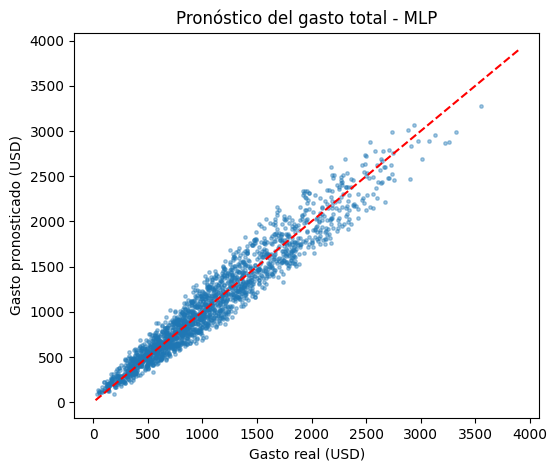

membership_years            1.1059
annual_income               0.4178
spending_score              0.3951
recencia_dias               0.0006
sentimiento                 0.0005
website_visits_per_month    0.0002
country                     0.0001
age                         0.0000
gender                      0.0000
cart_abandon_rate          -0.0003
dtype: float64


In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(yg_te, pred_mlp, s=6, alpha=0.4)
plt.plot([yg.min(), yg.max()], [yg.min(), yg.max()], "r--")
plt.xlabel("Gasto real (USD)"); plt.ylabel("Gasto pronosticado (USD)")
plt.title("Pronóstico del gasto total - MLP"); plt.show()

# ¿Qué variables explican el gasto?
pi_g = permutation_importance(reg_mlp, Xg_te, yg_te, n_repeats=10, random_state=42, n_jobs=-1)
print(pd.Series(pi_g.importances_mean, index=Xg.columns).sort_values(ascending=False).round(4))

In [ ]:
# Resumen para negocio: clientes con alto riesgo de churn por segmento
datos.loc[X_test.index, "prob_churn"] = y_proba
print(datos.groupby("segmento").agg(clientes=("churned", "size"), tasa_churn=("churned", "mean"),
                              gasto_prom=("gasto_total", "mean"), prob_churn_prom=("prob_churn", "mean")).round(3).to_string())

          clientes  tasa_churn  gasto_prom  prob_churn_prom
segmento                                                   
0             2491       0.032    1544.859            0.253
1             3792       0.039     594.791            0.424
2              788       1.000     739.433            0.692
3             2929       0.026    1495.190            0.241


## 7. Discusión de los resultados

### 7.1 Lo que encontramos en los datos antes de modelar

El primer hallazgo importante salió del análisis exploratorio y no de un modelo. Cerca del **10,9% de los clientes (1.090 de 10.000) abandonó la empresa**, lo que confirma que el churn es un evento poco frecuente y que la base está desbalanceada. Al comparar clientes activos contra clientes que se fueron aparecieron diferencias claras: los que abandonan tienen un **puntaje de gasto mucho más bajo (30,8 frente a 53,4)**, hacen **menos compras (17,5 frente a 23,2)**, llevan **menos años como miembros (4,9 frente a 6,5)**, **visitan menos el sitio web (12,5 frente a 16 visitas al mes)** y **abandonan más el carrito (63% frente a 49%)**. En cambio, la edad, el ingreso anual, el género y el país casi no cambian entre ambos grupos; la tasa de churn por país solo se mueve entre 9,7% (Canadá) y 12,8% (Reino Unido). Esto ya nos dice algo útil para el negocio: **el abandono no depende de quién es el cliente, sino de cómo se comporta con la tienda**.

El segundo hallazgo fue una **fuga de información (data leakage)**. Los 1.090 clientes que abandonaron dejaron un comentario negativo y ninguno de los que siguen activos lo hizo. Con esa variable, el primer árbol de decisión que entrenamos acertó el 100% de los casos. Ese resultado parecía excelente, pero en realidad era engañoso: un comentario como *"I will not be shopping here again"* se escribe cuando el cliente ya decidió irse, así que no sirve para anticiparse. Lo mismo ocurrió con la **recencia** (días desde la última compra): el segmento de clientes inactivos tiene 100% de churn, lo que indica que en esta base el churn se define justamente por llevar mucho tiempo sin comprar. Por eso sacamos el comentario, el sentimiento y la recencia de los modelos de clasificación. Este paso es clave para la credibilidad del proyecto: **un modelo con 66% de exactitud que sí se puede usar vale más que uno con 100% que no sirve en la práctica**.

### 7.2 Segmentación con K-means

Agrupamos a los clientes con ocho variables de comportamiento y valor (ingreso, puntaje de gasto, número de compras, valor promedio, antigüedad, visitas, abandono de carrito y recencia), estandarizadas como vimos en clase. El índice silhouette fue bajo en todos los valores de k (alrededor de 0,18 en el mejor caso), lo que significa que **los grupos no están perfectamente separados**: los clientes se parecen bastante entre sí y hay zonas de transición entre segmentos. Aun así, con k = 4 los grupos tienen perfiles muy distintos y fáciles de explicar al negocio:

- **Segmento 0 – "Alto valor" (2.491 clientes):** el ingreso más alto (≈130.600 USD), el mayor valor por compra (60,7 USD) y un gasto total promedio de 1.545 USD. Su churn es de apenas 3,2%.
- **Segmento 1 – "Nuevos de bajo valor" (3.792 clientes):** es el grupo más grande. Tienen solo 3 años de antigüedad, compran poco (14 compras) y gastan en promedio 595 USD. Su churn real hoy es bajo (3,9%), pero el modelo les asigna la probabilidad de churn más alta entre los clientes activos (42% en promedio). Es decir, **su comportamiento se parece al de los clientes que se van**.
- **Segmento 2 – "Inactivos / perdidos" (788 clientes):** llevan en promedio **522 días sin comprar**, tienen el puntaje de gasto más bajo (29) y el mayor abandono de carrito (65%). El 100% de este grupo ya abandonó la empresa.
- **Segmento 3 – "Leales veteranos" (2.929 clientes):** 11,6 años de antigüedad, el mayor número de compras (32,7) y un gasto de 1.495 USD. Tienen el churn más bajo (2,6%).

La lectura de negocio es clara: la empresa tiene dos grupos que generan la mayor parte de los ingresos (alto valor y leales), un grupo grande de clientes nuevos que todavía no se ha "enganchado" y un grupo ya perdido. **El grupo en el que más vale la pena invertir para retener es el de nuevos de bajo valor**, porque es grande, todavía está activo y se parece a los que se van.

### 7.3 Clasificación del churn: Árbol de Decisión frente a Red Neuronal

Sin las variables con fuga, el **Árbol de Decisión** (optimizado con GridSearchCV: profundidad 5, mínimo 50 registros para dividir y 20 por hoja, con clases balanceadas) logró en el conjunto de prueba:

| Métrica | Árbol de Decisión | Red Neuronal MLP |
|---|---|---|
| Exactitud | 66,2% | 70,0% |
| Sensibilidad (Recall) | **87,2%** | 61,5% |
| Especificidad | 63,7% | 71,0% |
| Precisión | 22,7% | 20,6% |
| F1 | **0,36** | 0,31 |
| AUC-ROC | **0,83** | 0,74 |

La exactitud de ambos modelos es más baja que el 89% que obtendría un modelo que diga que "nadie se va". Esto es esperable y no es un problema: en un caso de churn lo importante es **encontrar a los clientes que se van a ir**. En eso el árbol es claramente mejor: **detecta 87 de cada 100 clientes que abandonan**, mientras que la red neuronal detecta 61. El costo de esa alta sensibilidad es la precisión: de cada 100 clientes que el árbol marca como "en riesgo", unos 23 realmente se van. Para una campaña de retención esto es aceptable si la acción es barata (un correo, un cupón o una notificación), porque es mucho más costoso perder a un cliente que enviarle un beneficio a alguien que no lo necesitaba.

El **AUC de 0,83** del árbol indica que el modelo ordena bien a los clientes según su riesgo. Por eso no solo sirve para decir sí o no: también puede **priorizar** a los clientes, atendiendo primero a los de mayor probabilidad. La red neuronal (AUC 0,74) quedó por debajo, y al principio tuvo problemas para aprender. Como solo el 11% de los casos eran churn, la red se detenía muy rápido prediciendo que nadie se iba. Tuvimos que balancear el entrenamiento duplicando los casos de churn (sobremuestreo). Esto muestra una lección práctica: **un modelo más complejo no siempre es mejor**. Con datos tabulares y pocas variables, un árbol bien ajustado puede superar a una red neuronal y además es mucho más fácil de explicar a un gerente.

Según el árbol, las variables más importantes para predecir el abandono son el **puntaje de gasto (40% de la importancia)**, la **tasa de abandono del carrito (25%)**, las **visitas mensuales al sitio (18%)** y los **años como miembro (12%)**. La importancia por permutación confirma el mismo orden. País, género, edad e ingreso prácticamente no aportan. En lenguaje de negocio: **el cliente que se va es el que gasta poco, deja productos en el carrito, entra poco a la página y lleva poco tiempo con nosotros**. Todas son señales que la empresa puede observar en tiempo real y sobre las que puede actuar.

### 7.4 Pronóstico del gasto total con una Red Neuronal

Para pronosticar el gasto total de cada cliente (en promedio 1.107 USD) no usamos el número de compras ni el valor promedio, porque con ellos el gasto se calcula de forma directa. La **red neuronal MLP de regresión** obtuvo un **R² de 0,936**, un **error absoluto medio (MAE) de 119 USD** y un RMSE de 151 USD. Esto supera a la regresión lineal usada como línea base (R² de 0,915 y MAE de 139 USD). En términos simples, el modelo explica cerca del **94% de las diferencias de gasto entre clientes** y se equivoca en promedio en unos 119 USD, aproximadamente un 11% del gasto promedio.

Las variables que más explican el gasto son los **años como miembro**, el **ingreso anual** y el **puntaje de gasto**. Tiene sentido: los clientes con más antigüedad acumulan más compras y los de mayor ingreso compran productos más caros. La pequeña mejora de la red frente a la regresión lineal sugiere que la relación es casi lineal, con algunas interacciones que la red sí logra capturar.

### 7.5 Cómo se conectan los tres modelos

La mayor fortaleza del proyecto es que los modelos se complementan. K-means dice **qué tipos de clientes hay**. El árbol de decisión dice **quién está en riesgo de irse y por qué**. La red de regresión dice **cuánto vale cada cliente**. Si cruzamos riesgo y valor, la empresa puede construir una **matriz de prioridades**: los clientes con alto riesgo y alto gasto pronosticado deben recibir la atención más personalizada; los de alto riesgo y bajo valor pueden recibir acciones automáticas y baratas; y los de bajo riesgo pueden recibir campañas de fidelización o de venta cruzada. Así el presupuesto de retención se gasta donde genera más retorno, en lugar de repartirse igual entre todos los clientes.

## 8. Posibles limitaciones y retos

- **Datos posiblemente sintéticos:** la base parece generada para práctica: hay solo 12 comentarios distintos, todos los comentarios negativos corresponden a clientes que se fueron y las distribuciones son muy uniformes. Los resultados pueden ser distintos con datos reales de una empresa.
- **Fuga de información:** el comentario del cliente y la recencia revelan directamente el churn. Tuvimos que excluirlos, lo que dejó al modelo con menos información disponible.
- **Desbalance de clases:** solo el 11% de los clientes abandona, lo que baja la precisión de los modelos. Hubo que usar pesos balanceados en el árbol y sobremuestreo en la red neuronal.
- **Segmentos poco separados:** el índice silhouette fue bajo (≈0,18), así que algunos clientes quedan en la frontera entre dos segmentos.
- **Falta de tiempo en los datos:** solo hay una foto de cada cliente (y una fecha de última compra). Sin un historial mes a mes no se puede hacer un pronóstico de series de tiempo ni ver cómo cambia el riesgo de un cliente.
- **Variables que faltan:** no hay información de precios, promociones, reclamos, devoluciones ni de la competencia, que normalmente influyen mucho en el abandono.
- **Reto de uso:** el modelo necesita reentrenarse periódicamente, porque el comportamiento de los clientes cambia con el tiempo.

## 9. Consideraciones éticas y prácticas

- **Privacidad de los datos:** la base incluye datos personales (edad, género, país, ingreso). En Colombia su tratamiento debe cumplir la **Ley 1581 de 2012 de protección de datos personales**, con autorización del cliente y un uso limitado a la finalidad informada.
- **No discriminación:** verificamos que género, país y edad casi no influyen en el modelo, lo cual es positivo. Aun así, la empresa no debería usar variables sensibles para negar beneficios ni para tratar peor a un grupo de clientes.
- **Uso responsable de la predicción:** el modelo debe usarse para **ofrecer mejores experiencias** (beneficios, soporte, mejoras del sitio) y no para manipular a los clientes ni para cobrar más a quien probablemente se quede.
- **Transparencia:** elegimos el árbol de decisión también porque es explicable. Si un cliente recibe una oferta o un trato diferente, la empresa puede explicar las razones.
- **Errores del modelo:** cerca de 3 de cada 4 clientes marcados como "en riesgo" en realidad se quedarían. Las acciones deben ser de bajo costo y no invasivas, para no molestar a clientes satisfechos.
- **Práctico:** el modelo debe acompañar el criterio del equipo comercial, no reemplazarlo, y su desempeño debe monitorearse con datos nuevos.

## 10. Conclusiones

1. El abandono de clientes (10,9%) se explica por el **comportamiento con la tienda**, no por características demográficas: puntaje de gasto bajo, mucho abandono del carrito, pocas visitas y poca antigüedad.
2. Detectamos una **fuga de información** en los comentarios y en la recencia. Al quitarlos, obtuvimos modelos realistas y útiles, que es más valioso que una exactitud perfecta pero engañosa.
3. El **Árbol de Decisión** fue el mejor clasificador: detecta el **87% de los clientes que se van** (AUC 0,83) y es fácil de explicar. La red neuronal tuvo menor desempeño (AUC 0,74).
4. **K-means** identificó cuatro segmentos: alto valor, nuevos de bajo valor, inactivos y leales veteranos. El grupo de **nuevos de bajo valor (38% de los clientes)** es la mayor oportunidad de retención.
5. La **red neuronal de regresión** pronostica el gasto del cliente con un **R² de 0,94** y un error promedio de 119 USD, lo que permite estimar el valor de cada cliente y priorizar la inversión.
6. Combinar segmentación, riesgo y valor le permite a la empresa pasar de acciones generales a **acciones de retención focalizadas y medibles**.

## 11. Recomendaciones

1. **Implementar un sistema de alerta temprana:** calcular cada mes la probabilidad de churn de todos los clientes con el árbol de decisión y activar acciones automáticas para quienes superen el umbral.
2. **Atacar el abandono del carrito:** enviar recordatorios, cupones o envío gratis cuando un cliente deja productos en el carrito, porque es el segundo factor de mayor peso en el abandono.
3. **Programa de bienvenida para clientes nuevos:** el segmento de nuevos de bajo valor necesita incentivos durante sus primeros años (puntos, descuentos en la segunda o tercera compra) para que suba su gasto y su antigüedad.
4. **Aumentar el puntaje de gasto y las visitas:** usar recomendaciones personalizadas, contenido y notificaciones para que los clientes vuelvan al sitio con más frecuencia.
5. **Priorizar por valor:** cruzar el riesgo de churn con el gasto pronosticado y dar atención personalizada (asesor, beneficios premium) a los clientes de alto valor en riesgo.
6. **Campaña de reactivación** para el segmento inactivo (788 clientes con más de un año sin comprar), con una oferta fuerte y medible. Si no responden, no seguir invirtiendo en ellos.
7. **Proteger a los leales y de alto valor** con un programa de fidelización (niveles VIP, acceso anticipado) para mantener su churn bajo.
8. **Mejorar los datos:** registrar historial mensual de compras, reclamos, devoluciones y uso de promociones, y reentrenar los modelos cada trimestre.

## 12. Bibliografía

- Fares279. (2024). *Customers Transactions* [Conjunto de datos]. Kaggle. https://www.kaggle.com/datasets/fares279/customers-transactions
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3.ª ed.). O'Reilly Media.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2021). *An Introduction to Statistical Learning* (2.ª ed.). Springer.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Reichheld, F. F., & Sasser, W. E. (1990). Zero defections: Quality comes to services. *Harvard Business Review, 68*(5), 105–111.
- Universidad EAFIT. (2026). Material de clase Analítica de Negocios: K-means, Árboles de decisión, Naive Bayes y Redes Neuronales.